# Tutorial: running LASER on a mouse F1 hybrid

LASER is a Nextflow pipeline for long-read RNA-seq (PacBio Iso-Seq and Oxford Nanopore). It calls variants from the reads, phases them, assigns every read to a haplotype and then tests each gene for allele-specific expression (ASE) and allele-specific transcript usage.

This tutorial uses a small test dataset: 8 ENCODE long-read libraries from the B6 × CAST F1 hybrid mouse, subset to chromosome 17. The F1 hybrid is a standard model for ASE:

- Both parents are inbred, so every site where C57BL/6J (B6) and CAST/EiJ (CAST) differ is heterozygous in the F1. That gives a dense set of SNPs to phase on.
- The reference genome (GRCm38) is B6. So in a phased block, whichever haplotype carries the reference alleles is the B6 haplotype and the other is CAST. Section 4 uses this to turn "haplotype 1/2" into "B6/CAST".
- Chromosome 17 has high sequence diversity between laboratory and wild-derived strains. It carries the highly polymorphic MHC region and the imprinted *Igf2r*/*Airn* cluster, and it is a hotspot for cis-eQTLs.

The notebook shows you:

- (A) how to run LASER on the subset (`params.species = 'mouse'`, FASTQ entry via `pacbio_fastqentry`)
- (B) how to check that each stage of the run worked, then interpret the allelic results

Every cell reads only files that the tutorial run writes, so it should run as-is after `scripts/2_run_tutorial.sh` finishes.

## (A) Running the tutorial

Follow the setup in the [LASER README](https://github.com/MacphersonHannah/LASER-1.1):

1. Install the conda environments.
2. Download the tutorial data (FASTQs and chr17 references):
   ```bash
   bash tutorial/scripts/1_download_data.sh
   ```
3. Check the paths in `tutorial/scripts/tutorial.config`.
4. Submit the run and wait for it to finish:
   ```bash
   sbatch tutorial/scripts/2_run_tutorial.sh     # or: bash tutorial/scripts/run_tutorial.sh
   ```
5. Outputs are written to `run_tutorial/tutorial/`, in one folder per pipeline stage:

| stage folder | what LASER did | used in this notebook for |
|---|---|---|
| `preprocessing/` | clustering, alignment (pbmm2), isoform collapse, DeepVariant | variant-calling QC (section 1) |
| `identify_loci/` | WhatsHap phasing and haplotagging, gene counts | phasing QC (section 2) |
| `annotate_isoforms/` | SQANTI3, ORFannotate/CPAT, allele-resolved read counts | isoform QC (section 5), all allelic analyses |
| `allelic_effect_testing/` | abTE and abTU tests, theta calibration, consequence analysis | sections 6–10 |
| `report_*.html`, `timeline_*.html`, `trace_*.txt` | Nextflow run reports | open in a browser for runtime and memory |

## Terminology

- abTE, *allelic bias in total expression*: is the gene expressed more from one allele? This is a binomial test on the allele-1 and allele-2 read totals, with an effect-size guard (the major-allele fraction must pass `abte_major_frac_threshold`).
- abTU, *allelic bias in transcript usage*: do the two alleles use a different mix of isoforms? This is a permutation Dirichlet-Multinomial test on the per-transcript allele counts. The effect size is the **TVD** (total variation distance) between the two alleles' usage vectors.

Every tested gene falls into one of four classes: **abTE only**, **abTU only**, **both** or **neither**. The interesting case biologically, and the one only long reads can see, is **abTU without abTE**: both alleles produce the same amount of RNA, but as different transcripts.

**Theta** is the Dirichlet-Multinomial overdispersion parameter. The tutorial uses `theta_mode = 'calibrate_pooled'`, which pools samples to estimate theta. Pooled calibration needs more than 2 samples. With exactly 2 it warns, with fewer it stops with an error, and then you should switch to `lift` or `fixed`.

## Setup

Set `OUT_DIR` to the run's output folder and `REF_DIR` to the tutorial reference folder. If you leave them as `None`, the cell looks in the usual places relative to the notebook. You can also set the environment variables `LASER_OUT` and `LASER_REF`.

`CROSS_MATERNAL` sets which strain is the mother. It is only used to predict the direction of the imprinting controls. ENCODE's B6CASTF1/J mice come from a C57BL/6J female × CAST/EiJ male cross, but check the biosample page if you use other data.

In [61]:
from pathlib import Path
import io, os, re, gzip, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from gtfparse import read_gtf

# Settings
OUT_DIR = Path(os.environ.get("LASER_OUT", "../../run_tutorial/tutorial")).resolve()
REF_DIR = Path(os.environ.get("LASER_REF", "../../tutorial/data/reference")).resolve()
CROSS_MATERNAL = "B6"
SAVE_OUTPUTS = True

#make this more explicitly the same as the scripts folder with  Path("notebook_outputs/figures")
FIG_DIR = Path("./notebook_outputs/figures")
if SAVE_OUTPUTS: FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

def finish(fig, name):
    fig.tight_layout()
    if SAVE_OUTPUTS: fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def read_vcf(path):
    rows = []
    with (gzip.open(path, "rt") if str(path).endswith(".gz") else open(path)) as fh:
        for line in fh:
            if line.startswith("#"): continue
            f = line.rstrip().split("\t")
            if len(f) >= 10:
                d = dict(zip(f[8].split(":"), f[9].split(":")))
                rows.append((f[0], int(f[1]), f[3], f[4], f[6], d.get("GT", "."), d.get("PS", ".")))
    return pd.DataFrame(rows, columns=["chrom", "pos", "ref", "alt", "filter", "gt", "ps"])
def n50(lengths):
    l = np.sort(np.asarray(lengths))[::-1]
    if l.size == 0:
        return np.nan
    c = np.cumsum(l)
    return l[np.searchsorted(c, c[-1] / 2)]


print("Setup completed.")

Setup completed.


## 0. Did the run finish? Output inventory

Before analysing anything, check that each stage wrote its outputs for every sample. A missing file usually means a process failed. The Nextflow `report_*.html` shows which one and why.

In [62]:
AE_DIR = OUT_DIR / "allelic_effect_testing"
# Subfolders that hold run-level outputs rather than one library each
NON_SAMPLE = {"overview"}
SAMPLES = sorted(p.name for p in AE_DIR.iterdir()
                 if p.is_dir() and not p.name.startswith("_") and p.name not in NON_SAMPLE)

PER_SAMPLE = {
    "DeepVariant VCF": "preprocessing/run_deepvariant/{s}/DeepVariant/{s}/{s}.deepvariant.vcf.gz",
    "phased VCF": "identify_loci/whatshap/{s}/phased.vcf.gz",
    "gene counts": "identify_loci/count_genes/{s}/{s}.gene_expression.tsv",
    "allelic_effect_results": "allelic_effect_testing/{s}/allelic_effect_results.tsv",
}

inv = pd.DataFrame({k: ["✔" if (OUT_DIR / v.format(s=s)).exists() else "✘" for s in SAMPLES] for k, v in PER_SAMPLE.items()}, index=SAMPLES)
display(inv)

,DeepVariant VCF,phased VCF,gene counts,allelic_effect_results
ENCFF100UBG,✔,✔,✔,✔
ENCFF338YTG,✔,✔,✔,✔
ENCFF476MLA,✔,✔,✔,✔
ENCFF509RDZ,✔,✔,✔,✔
ENCFF605NQH,✔,✔,✔,✔
ENCFF683BZL,✔,✔,✔,✔
ENCFF812RTU,✔,✔,✔,✔
ENCFF937WKF,✔,✔,✔,✔


### Load the core tables

| file | grain | what it gives you |
|---|---|---|
| `annotate_isoforms/transcript_summary/read_counts_summary.csv` | sample × transcript × haplotype | raw allele-resolved counts. Rows with an empty `bulk_pbid` are reads where no transcript could be called; they are dropped before any allelic analysis |
| `allelic_effect_testing/<sample>/allelic_effect_results.tsv` | sample × gene | **LASER's own** abTE/abTU statistics and calls |
| `allelic_effect_testing/overview/allelic_effect_summary.tsv` | one row per sample | eligibility waterfall, class proportions, theta used (also split per sample as `<sample>/sample_manifest_<sample>.tsv`) |
| `allelic_effect_testing/overview/consequence_test_summary.tsv` | one row per sample | functional consequence axes (`prop_sig_*`) |
| `allelic_effect_testing/_theta/theta_pooled*.json` | one per theta group | the calibrated θ, the false-positive rate it achieved on the calibration loci (`achieved_fpr`) against the target (`nominal_fpr`), and how many loci were used (`n_loci_used`) |
| `config_used_<run>.config` | one per run | thresholds the run used (`min_phased_reads_per_locus`, `abte_fdr_threshold`, `abte_major_frac_threshold`) |

The cell below prints the thresholds it read from the config, so you can check they match the run.

In [63]:
# Load read counts
reads = pd.read_csv(OUT_DIR / "annotate_isoforms/transcript_summary/read_counts_summary.csv")
# Rows with no bulk_pbid are reads where no transcript could be called. They are kept
# only to report how many reads were lost at that step, and are not used in any allelic analysis.
no_tx = reads[reads["bulk_pbid"].isna()].copy()
tx = reads[reads["bulk_pbid"].notna()].copy()
tx["gene_key"] = tx["associated_gene"].astype(str).str.replace(r"\.\d+.*$", "", regex=True)

# Per-sample summary table: eligibility waterfall, class proportions, theta used
run_manifest = pd.read_csv(AE_DIR / "overview/allelic_effect_summary.tsv", sep="\t")

# Thresholds come from the config Nextflow ran with
cfg = next(OUT_DIR.glob("config_used_*.config"))
PARAMS = {}
for l in cfg.read_text().splitlines():
    m = re.match(r"\s*(\w+)\s*=\s*['\"]?([^'\"\s]+)", l)
    if m: PARAMS.setdefault(m.group(1), m.group(2))

MIN_PHASED_READS = int(PARAMS["min_phased_reads_per_locus"])
FDR_ALPHA = float(PARAMS["abte_fdr_threshold"])
MAJOR_FRAC_GUARD = float(PARAMS["abte_major_frac_threshold"])
print(f"Thresholds from {cfg.name}: min_phased_reads={MIN_PHASED_READS}, "
      f"FDR={FDR_ALPHA}, major_frac={MAJOR_FRAC_GUARD}")

# Load allelic effect results
dfs = []

for s in SAMPLES:
    file_path = AE_DIR / s / "allelic_effect_results.tsv"
    
    if file_path.exists():
        df = pd.read_csv(file_path, sep="\t")
        df["sample"] = s
        
        # Standardize column names if needed
        col_map = {
            "n_hap1": "a1", "hap1_count": "a1", "hap1_reads": "a1",
            "n_hap2": "a2", "hap2_count": "a2", "hap2_reads": "a2"
        }
        df = df.rename(columns=col_map)
        
        dfs.append(df)

ae = pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()

# Counts aggregated at gene level
phased_tx = tx[tx["haplotype"].isin(["1", "2"])]
counts = phased_tx.groupby(["sample", "gene_key", "haplotype"])["count"].sum().unstack(fill_value=0).rename(columns={"1": "a1", "2": "a2"}).reset_index()
counts["total"] = counts["a1"] + counts["a2"]
counts["ratio"] = counts["a1"] / counts["total"]
print("Tables successfully loaded.")

Thresholds from config_used_tutorial_20261008_083058.config: min_phased_reads=30, FDR=0.05, major_frac=0.55
Tables successfully loaded.


### Gene and transcript annotation

Gene names and coordinates come from the GENCODE GTF in `REF_DIR`. Transcript structures come from SQANTI's corrected GTF. The IDs in that GTF (`PB.x.y`) match `bulk_pbid`.

In [64]:
# Load reference genes using gtfparse
genes_ref = pd.DataFrame()
gtf_file = next(REF_DIR.glob("*.gtf"), None)
if gtf_file:
    df_gtf = read_gtf(gtf_file)
    if hasattr(df_gtf, "to_pandas"):  # Compatibility for gtfparse >= 2.0 (Polars output)
        df_gtf = df_gtf.to_pandas()
    genes_ref = df_gtf[df_gtf["feature"] == "gene"].copy()
    genes_ref["gene_key"] = genes_ref["gene_id"].str.replace(r"\.\d+.*$", "", regex=True)

# SQANTI classification table
sq_path = OUT_DIR / "annotate_isoforms/SQANTI_QC/Sqanti/bulk/bulk_classification.txt"
sq = pd.read_csv(sq_path, sep="\t") if sq_path.exists() else None

# Load corrected GTF transcript models using gtfparse
gtf_corr = OUT_DIR / "annotate_isoforms/SQANTI_QC/Sqanti/bulk/bulk_corrected.gtf"
if gtf_corr.exists():
    df_corr = read_gtf(gtf_corr)
    if hasattr(df_corr, "to_pandas"):
        df_corr = df_corr.to_pandas()
    tx_models = df_corr[df_corr["feature"] == "exon"].copy()
else:
    tx_models = pd.DataFrame()

# Gene name dictionary lookup
gene_map = dict(zip(genes_ref["gene_key"], genes_ref["gene_name"])) if "gene_key" in genes_ref else {}
gname = lambda k: gene_map.get(k, k)

## 1. Variant calling (DeepVariant)

LASER calls SNVs (single-nucleotide variants) directly from the long reads, so no separate DNA genotyping is needed. Because the sample is a B6 × CAST F1 hybrid, every B6/CAST difference should be heterozygous. The variant calls should therefore show:

- **Mostly heterozygous calls.** As a B6 × CAST F1 hybrid, almost all calls should be heterozygous.

- **A Ti/Tv ratio of ~2.0–2.2.** Ti/Tv is the ratio of transitions to transversions. Nucleotide bases fall into two families: purines (A, G) and pyrimidines (C, T).
  - A **transition (Ti)** swaps a base for another in the same family (A ↔ G or C ↔ T).
  - A **transversion (Tv)** swaps a base across families (A ↔ C, A ↔ T, G ↔ C or G ↔ T).

  There are twice as many possible transversions as transitions, so random substitutions would give a ratio of about 0.5. Biologically, though, transitions are far more common. They are an easier mistake for DNA polymerases to make and for proofreading to miss. They are also less likely to change the amino acid sequence, so selection tolerates them better. Mammalian genomes have a Ti/Tv of around 2.0–2.2:
  - A ratio **below** this range suggests sequencing errors or random noise.
  - A ratio **above** 2.2 could reflect A-to-I RNA editing, which appears as A → G transitions.

- **Consistent het sites across samples.** All samples share the same F1 genotype, so the same het sites should appear wherever a gene is expressed. The six main samples show high sharing (green squares in Fig. 1). The score is around 0.5–0.6 rather than 1.0 because RNA-seq only detects variants in expressed genes, and different tissues and libraries express different genes at different read depths. Samples 2 (ENCFF476MLA) and 5 (ENCFF683BZL) are the exceptions. They have almost no variants, which points to failed or shallow runs (Fig. 1).

In the six good libraries, Ti/Tv is ~2.6–2.8, above the genome-wide range in the green band. This is expected for RNA-derived calls: variants can only be called in expressed sequence, mostly exons and UTRs, and coding regions have a higher Ti/Tv (~2.8–3.0) than the genome as a whole. A-to-I editing may add a little on top.

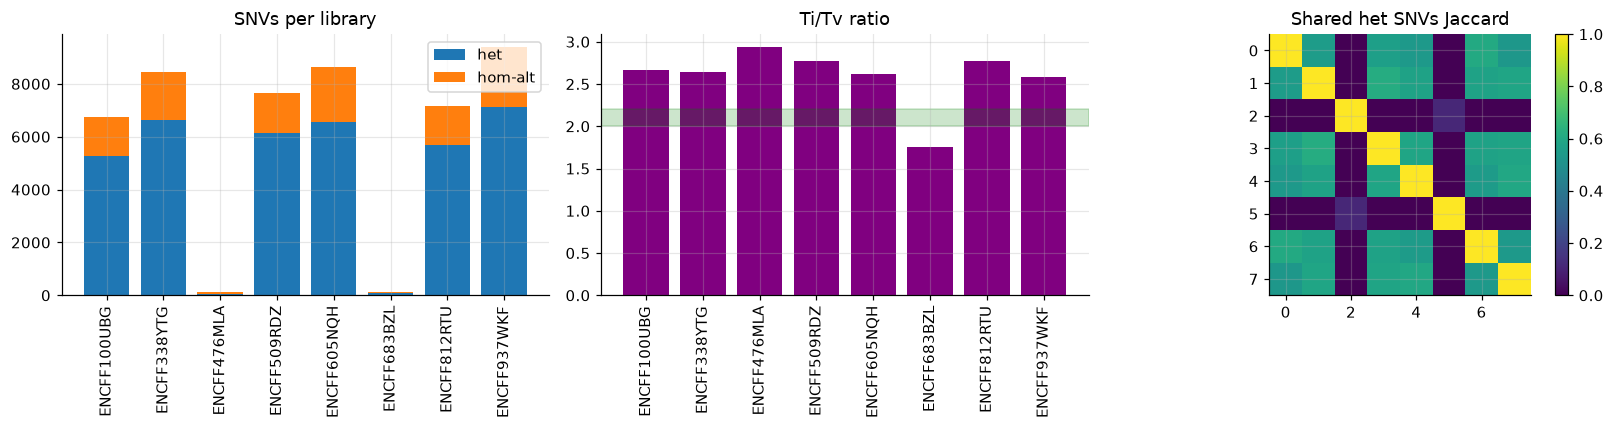

In [65]:
# Transition base pairs for Ti/Tv ratio
TRANSITIONS = {("A", "G"), ("G", "A"), ("C", "T"), ("T", "C")}

dv_rows, dv_sites = [], {}

# 1. Process VCF for each sample
for s in SAMPLES:
    vcf_path = OUT_DIR / f"preprocessing/run_deepvariant/{s}/DeepVariant/{s}/{s}.deepvariant.vcf.gz"
    if not vcf_path.exists():
        continue
    
    vcf = read_vcf(vcf_path)
    vcf = vcf[(vcf["filter"] == "PASS") & ~vcf["gt"].isin([".", "0/0"])]
    
    # Filter for Single Nucleotide Variants (SNVs)
    snv = vcf[(vcf["ref"].str.len() == 1) & (vcf["alt"].str.len() == 1)]
    
    gt = snv["gt"].str.replace("|", "/", regex=False)
    het = snv[gt.isin(["0/1", "1/0"])]
    hom = snv[gt == "1/1"]
    
    # Vectorized Ti/Tv calculation
    pairs = list(zip(snv["ref"], snv["alt"]))
    ti_count = sum(pair in TRANSITIONS for pair in pairs)
    tv_count = max(len(snv) - ti_count, 1)
    
    dv_sites[s] = set(zip(het["chrom"], het["pos"]))
    dv_rows.append({
        "sample": s, 
        "het_snvs": len(het), 
        "homalt_snvs": len(hom), 
        "het_frac": len(het) / max(len(snv), 1), 
        "ti_tv": ti_count / tv_count
    })

dv = pd.DataFrame(dv_rows).set_index("sample") if dv_rows else pd.DataFrame()

# 2. Build Jaccard Similarity Matrix
jac = pd.DataFrame(index=SAMPLES, columns=SAMPLES, dtype=float)
for s1 in SAMPLES:
    for s2 in SAMPLES:
        set1, set2 = dv_sites.get(s1, set()), dv_sites.get(s2, set())
        intersection = len(set1 & set2)
        union = len(set1 | set2)
        jac.loc[s1, s2] = intersection / union if union > 0 else 0.0

# 3. Generate Plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

if not dv.empty:
    axes[0].bar(dv.index, dv["het_snvs"], label="het")
    axes[0].bar(dv.index, dv["homalt_snvs"], bottom=dv["het_snvs"], label="hom-alt")
    axes[0].set_title("SNVs per library")
    axes[0].tick_params(axis="x", rotation=90)
    axes[0].legend()

    axes[1].bar(dv.index, dv["ti_tv"], color="purple")
    axes[1].axhspan(2.0, 2.2, color="green", alpha=0.2)
    axes[1].set_title("Ti/Tv ratio")
    axes[1].tick_params(axis="x", rotation=90)

    im = axes[2].imshow(jac.astype(float), vmin=0, vmax=1)
    axes[2].set_title("Shared het SNVs Jaccard")
    fig.colorbar(im, ax=axes[2])

finish(fig, "01_variant_calling")

## 2. Phasing (WhatsHap)

WhatsHap links het SNVs into **phase blocks** using reads that span several SNVs. Long reads are what make blocks long enough to cover whole genes. Three things to check:

1. **Phased fraction**: what proportion of het SNVs ended up in a block. ~98–99% of het SNVs are placed in a phase block. 
2. **Block N50**: how long the blocks are (genomic span). It should be at least gene length (tens of kb), or genes get split across blocks. ~82–99 kb, longer than a typical mouse gene, so most genes fall within a single block. Blocks this long are more than you might expect from RNA. Block span is genomic, so a single spliced read across a long intron links SNVs tens of kb apart, and transcriptional read-through into neighbouring genes can join blocks across genes.
3. **Block consistency**, which only works in an inbred F1. Every CAST allele is ALT (the reference is B6), so within a correctly phased block, *all* ALT alleles should sit on the same haplotype (all `0|1` or all `1|0`). Sites that disagree with their block's majority are switch errors. 99.1–99.8% of sites agree with their block's majority haplotype. The small remainder is consistent with residual calling errors.

ENCFF476MLA and ENCFF683BZL, the same samples that yielded almost no variants in Section 1, fail on every metric. Only ~47% and ~57% of their het SNVs are phased, their block N50s are ~8 kb and ~1–2 kb, and only ~89% and ~83% of their sites are concordant. This fits a shallow-run explanation: with few reads, fewer reads span multiple SNVs, so blocks stay short, and a larger share of the het calls are likely errors. These two samples are excluded from downstream allele-specific analyses.


,n_het,phased_frac,n_blocks,block_n50_kb,site_consistency,frac_blocks_clean
sample,,,,,,
ENCFF100UBG,5233,0.983,481,98.965,0.995,0.977
ENCFF338YTG,6603,0.986,500,92.121,0.991,0.966
ENCFF476MLA,60,0.467,8,8.610,0.889,0.750
ENCFF509RDZ,6119,0.982,469,91.068,0.998,0.979
ENCFF605NQH,6509,0.985,454,95.198,0.995,0.967
ENCFF683BZL,67,0.567,10,1.490,0.833,0.800
ENCFF812RTU,5680,0.987,494,82.656,0.997,0.988
ENCFF937WKF,7088,0.984,482,91.373,0.995,0.975


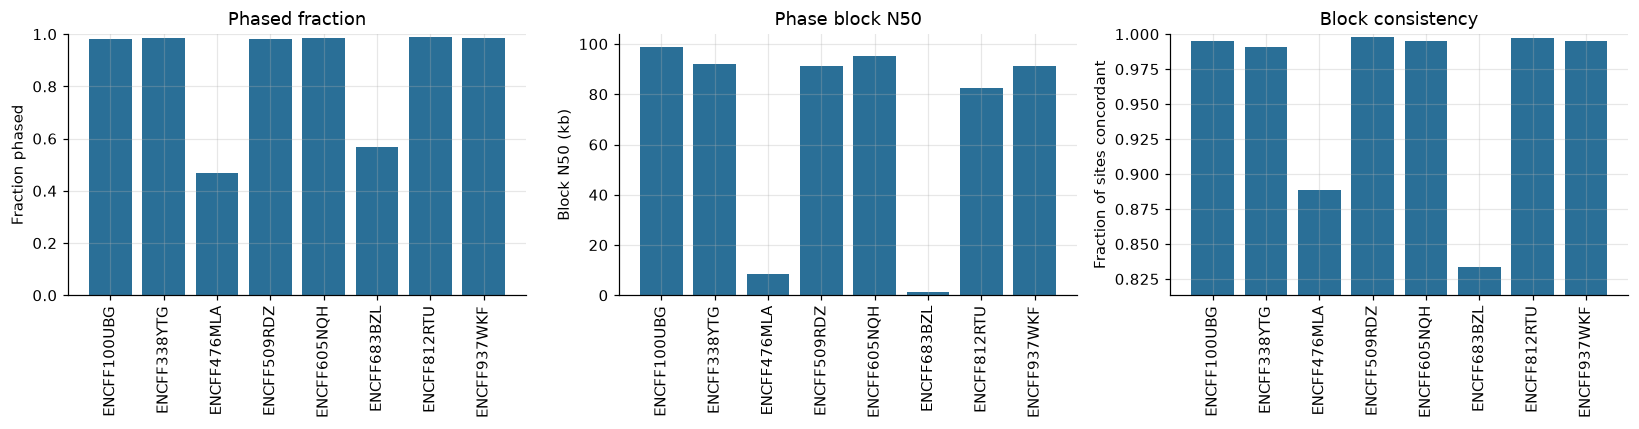

In [66]:
phase_rows, phased_sites, phase_blocks = [], {}, {}
for s in SAMPLES:
    p = OUT_DIR / f"identify_loci/whatshap/{s}/phased.vcf.gz"
    if not p.exists(): continue
    v = read_vcf(p)
    v = v[(v["filter"] == "PASS") & (v["ref"].str.len() == 1) & (v["alt"].str.len() == 1)]
    het = v[v["gt"].str.replace("|", "/").isin(["0/1", "1/0"])]
    ph = het[het["gt"].str.contains(r"\|") & (het["ps"] != ".")]
    ph = ph.assign(hap1_is_ref=ph["gt"].str.startswith("0"))
    phased_sites[s] = ph

    # One row per phase block (PS IDs are only unique within a chromosome)
    b = ph.groupby(["chrom", "ps"]).agg(
        start=("pos", "min"), end=("pos", "max"),
        n_sites=("pos", "size"), n_hap1_ref=("hap1_is_ref", "sum"),
    )
    b = b[b["n_sites"] >= 2]
    b["span"] = b["end"] - b["start"] + 1
    # In a B6-referenced F1 every ALT is CAST, so a correct block is all 0|1 or all 1|0.
    # Sites on the minority orientation are discordant.
    b["n_discordant"] = np.minimum(b["n_hap1_ref"], b["n_sites"] - b["n_hap1_ref"])
    phase_blocks[s] = b

    phase_rows.append({
        "sample": s,
        "n_het": len(het),
        "phased_frac": len(ph) / max(len(het), 1),
        "n_blocks": len(b),
        "block_n50_kb": n50(b["span"]) / 1e3,
        "site_consistency": 1 - b["n_discordant"].sum() / max(b["n_sites"].sum(), 1),
        "frac_blocks_clean": (b["n_discordant"] == 0).mean() if len(b) else np.nan,
    })

phasing = pd.DataFrame(phase_rows).set_index("sample") if phase_rows else pd.DataFrame()
display(phasing.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
ax.bar(phasing.index, phasing["phased_frac"], color="#2a6f97")
ax.set(ylim=(0, 1), ylabel="Fraction phased", title="Phased fraction")

ax = axes[1]
ax.bar(phasing.index, phasing["block_n50_kb"], color="#2a6f97")
ax.set(ylabel="Block N50 (kb)", title="Phase block N50")

ax = axes[2]
ax.bar(phasing.index, phasing["site_consistency"], color="#2a6f97")
lo = min(0.9, phasing["site_consistency"].min() - 0.02)
ax.set(ylim=(lo, 1), ylabel="Fraction of sites concordant", title="Block consistency")

for ax in axes:
    ax.tick_params(axis="x", rotation=90)
finish(fig, "02_phasing")

## 3. Read phasing and locus eligibility

After haplotagging, each read is labelled **haplotype 1**, **haplotype 2** or **unphased**. A read is unphased when it overlaps no informative (phased, heterozygous) SNV. Libraries with a high unphased fraction carry little allelic information.

Fig. 3 uses only reads that were assigned to a transcript (rows with a `bulk_pbid`), because those are the reads LASER tests. The cell also prints how many reads had no transcript call and the phased fraction per library. In the six good libraries, 73–82% of reads have no transcript call, and 78–84% of the transcript-assigned reads are phased. In ENCFF476MLA and ENCFF683BZL only 1–2% are phased, consistent with their failure in Sections 1 and 2. The hap 1 vs hap 2 split is not meaningful at the library level: WhatsHap numbers the haplotypes independently in each phase block, so haplotype 1 is B6 in some blocks and CAST in others.

Loci are then filtered before testing. A locus is excluded if:

1. **Not in the reference:** the gene is absent from the reference annotation.
2. **Fewer than 2 transcripts:** abTU cannot be tested with only one isoform.
3. **Too few reads:** the locus has fewer than `min_phased_reads_per_locus` phased reads in total, or fewer than `min_reads_per_haplotype` on either allele.

In this chr17 subset with subsampled FASTQs, most loci are expected to be excluded by the read-depth filter.

,reads_no_transcript,frac_no_transcript,frac_phased
sample,,,
ENCFF100UBG,35188,0.735,0.780
ENCFF338YTG,50634,0.734,0.775
ENCFF476MLA,56042,0.565,0.023
ENCFF509RDZ,42847,0.732,0.782
ENCFF605NQH,46219,0.803,0.826
ENCFF683BZL,64816,0.579,0.011
ENCFF812RTU,45227,0.745,0.780
ENCFF937WKF,67944,0.824,0.835


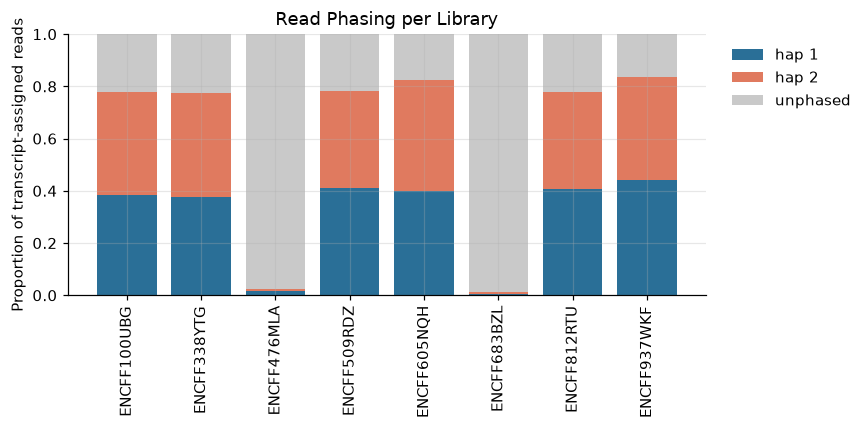

In [67]:
PALETTE = {"1": "#2a6f97", "2": "#e07a5f", "unphased": "#c9c9c9"}
LABELS = {"1": "hap 1", "2": "hap 2", "unphased": "unphased"}

# Use only reads assigned to a transcript (the reads LASER tests)
tx_hap = tx.assign(haplotype=tx["haplotype"].astype(str))
prop = tx_hap.pivot_table(index="sample", columns="haplotype", values="count", aggfunc="sum", fill_value=0)
prop = prop.div(prop.sum(axis=1), axis=0)

# How many reads had no transcript call, and what fraction of the rest are phased
n_tx = tx.groupby("sample")["count"].sum()
n_no_tx = no_tx.groupby("sample")["count"].sum().reindex(n_tx.index, fill_value=0)
summary = pd.DataFrame({
    "reads_no_transcript": n_no_tx,
    "frac_no_transcript": n_no_tx / (n_tx + n_no_tx),
    "frac_phased": prop[[c for c in ["1", "2"] if c in prop.columns]].sum(axis=1),
})
display(summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
bottom = np.zeros(len(prop))
for col in ["1", "2", "unphased"]:
    if col in prop.columns:
        ax.bar(prop.index, prop[col], bottom=bottom, label=LABELS[col], color=PALETTE[col])
        bottom += prop[col].values
ax.set(ylabel="Proportion of transcript-assigned reads", title="Read Phasing per Library", ylim=(0, 1))
ax.tick_params(axis="x", rotation=90)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
finish(fig, "03_read_phasing_eligibility")


## 4. From haplotype 1/2 to B6/CAST, and the reference-bias check

**Important caveat:** WhatsHap's haplotype 1 is *arbitrary within each phase block*. In one block hap 1 may be B6, in the next it may be CAST, and the assignment is made independently in every sample. Raw allele-1 fractions therefore can't be compared between genes or between samples.

The F1 model fixes this. Within each block, the haplotype carrying the **reference** alleles is B6. For each gene and sample, we take the het SNVs inside the gene and orient it by majority vote: if most of its SNVs have REF on hap 1, hap 1 is B6; otherwise hap 1 is CAST. Read counts are then relabelled as B6 and CAST. The two failed libraries (ENCFF476MLA and ENCFF683BZL) are excluded.

With alleles oriented, we can test for reference bias. CAST reads differ from the B6 reference at roughly one SNP per 100–150 bp, so they align slightly worse. Mapping bias would therefore push the B6 fraction above 0.5 across all genes, whereas genuine cis effects act in both directions and roughly cancel out.

The oriented B6 fractions centre close to 0.5 but lean slightly towards B6 (Fig. 4):

- **Pooled B6 fraction (all reads):** 0.528
- **Median per-gene B6 fraction** (each gene pooled across samples): 0.512
- **Direction of imbalance:** 289 genes favour B6 and 230 favour CAST (sign test, p = 0.011)

This is a small but significant B6 excess, consistent with mild reference mapping bias. The pooled fraction is weighted by read count, so it is pulled more strongly by highly expressed genes than the per-gene median is.

The spikes at 0 and 1 (~170 and ~200 locus–sample pairs) and the tall bar at exactly 0.5 likely reflect loci with very few reads, where the B6 fraction can only take a handful of values (0, ½, 1, ⅓, ⅔ and so on). A few may be genuinely monoallelic, for example imprinted genes.

Pooled B6 fraction (all reads): 0.528
Median per-gene B6 fraction:    0.512
Genes B6 > CAST: 289, CAST > B6: 230, sign test p = 0.011


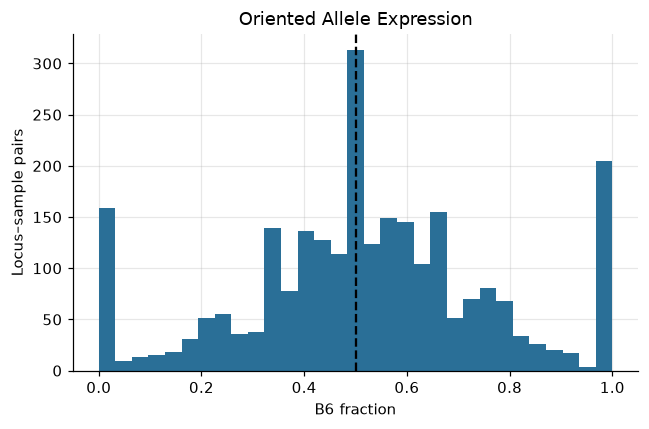

In [68]:
orient_rows = []
if not genes_ref.empty and phased_sites:
    for s, sites in phased_sites.items():
        left = sites.assign(chrom=sites["chrom"].astype(str)).sort_values("pos")
        right = genes_ref.assign(seqname=genes_ref["seqname"].astype(str)).sort_values("start")
        merged = pd.merge_asof(left, right, left_on="pos", right_on="start", left_by="chrom", right_by="seqname")
        merged = merged[merged["pos"] <= merged["end"]]
        for (key), grp in merged.groupby("gene_key"):
            orient_rows.append({"sample": s, "gene_key": key, "frac_hap1_ref": grp["hap1_is_ref"].mean()})

orient = pd.DataFrame(orient_rows)
if not orient.empty:
    orient["hap1_is_B6"] = orient["frac_hap1_ref"] >= 0.5
    oc = counts.merge(orient, on=["sample", "gene_key"], how="inner")
    oc["B6"] = np.where(oc["hap1_is_B6"], oc["a1"], oc["a2"])
    oc["CAST"] = np.where(oc["hap1_is_B6"], oc["a2"], oc["a1"])
    oc["b6_frac"] = oc["B6"] / oc["total"]
else:
    oc = pd.DataFrame()
from scipy.stats import binomtest

FAILED = ["ENCFF476MLA", "ENCFF683BZL"]

fig, ax = plt.subplots(figsize=(6, 4))
if not oc.empty:
    oc = oc[~oc["sample"].isin(FAILED)]
    ax.hist(oc["b6_frac"], bins=np.linspace(0, 1, 32), color="#2a6f97")
    ax.axvline(0.5, color="k", linestyle="--")
    ax.set(xlabel="B6 fraction", ylabel="Locus–sample pairs", title="Oriented Allele Expression")
    ax.set_axisbelow(True)

    # Pool each gene across samples so every gene counts once
    per_gene = oc.groupby("gene_key")[["B6", "total"]].sum()
    per_gene["b6_frac"] = per_gene["B6"] / per_gene["total"]
    n_b6 = (per_gene["b6_frac"] > 0.5).sum()
    n_cast = (per_gene["b6_frac"] < 0.5).sum()
    print(f"Pooled B6 fraction (all reads): {oc['B6'].sum() / oc['total'].sum():.3f}")
    print(f"Median per-gene B6 fraction:    {per_gene['b6_frac'].median():.3f}")
    print(f"Genes B6 > CAST: {n_b6}, CAST > B6: {n_cast}, "
          f"sign test p = {binomtest(n_b6, n_b6 + n_cast).pvalue:.2g}")
finish(fig, "04_orientation_reference_bias")

## 5. Isoform discovery QC (SQANTI3 + CPAT)

Before testing allelic usage, check the isoforms themselves. LASER runs SQANTI3 against the GENCODE annotation, using the tutorial's **refTSS** (CAGE TSS) and **PolyA atlas** files as independent evidence for transcript ends. SQANTI3 assigns each isoform a structural category:

- **FSM (full-splice match):** matches all splice junctions of a known transcript.
- **ISM (incomplete-splice match):** matches a consecutive subset of a known transcript's junctions.
- **NIC (novel in catalog):** a new combination of known splice sites.
- **NNC (novel not in catalog):** uses at least one new splice site.
- **Antisense, genic intron, intergenic, genic, fusion:** isoforms on the opposite strand of a known gene, inside an intron, between genes, partly overlapping a gene's exons and introns, or spanning two genes.

A novel isoform whose 5′ end falls in a refTSS peak and whose 3′ end falls near a PolyA-atlas site is very unlikely to be a degradation or internal-priming artefact.

CPAT then scores each isoform's ORF for coding potential. The standard mouse cut-off is 0.44.

FSM is the largest category (~4,800 isoforms), followed by ISM (~3,600), NNC (~3,500) and NIC (~2,100) (Fig. 5, left). Antisense, intronic, intergenic and genic isoforms make up a smaller tail, and fusions are rare (<100). CPAT scores are strongly bimodal (Fig. 5, right): most isoforms score close to 1, with a smaller peak below 0.2, so the large majority are predicted to be protein-coding.

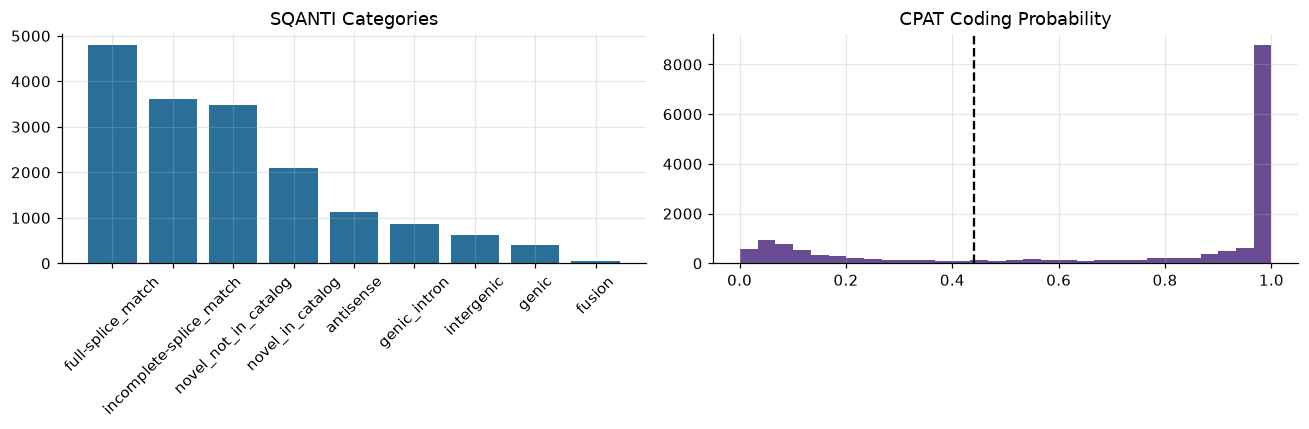

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if sq is not None:
    cat_counts = sq["structural_category"].value_counts()
    axes[0].bar(cat_counts.index, cat_counts.values, color="#2a6f97")
    axes[0].set_title("SQANTI Categories"); axes[0].tick_params(axis="x", rotation=45)

cpat_p = OUT_DIR / "annotate_isoforms/ORFANNOTATE/ORFannotate/bulk/CPAT/cpat.ORF_prob.best.tsv"
if cpat_p.exists():
    cpat = pd.read_csv(cpat_p, sep="\t")
    prob_col = [c for c in cpat.columns if "prob" in c.lower()][0]
    axes[1].hist(cpat[prob_col], bins=30, color="#6a4c93")
    axes[1].axvline(0.44, color="k", linestyle="--")
    axes[1].set_title("CPAT Coding Probability")
finish(fig, "05_isoform_qc")

## 6. abTE: allelic bias in total expression

abTE asks whether a gene is expressed more from one allele. This section plots LASER's own calls from `allelic_effect_results.tsv`, oriented with the B6/CAST labels from Section 4. The two failed libraries and loci that could not be oriented are left out.

**Left: volcano.** Each point is one gene in one library, plotted at log2(B6 / CAST). Blue points are significant (FDR < 0.05 and major-allele fraction above `abte_major_frac_threshold`); grey points are not. FDR is capped at 10⁻¹⁰ for display.

**Right: two example genes.** The cell picks the most reproducible B6-biased gene and the most reproducible CAST-biased gene: those called significant in the most libraries, leaning the same way in each. Each point is one library. A real effect sits on the same side of 0.5 in every library.

**Why MHC genes.** The strongest, most reproducible abTE signals on chr17 are in the MHC, so the examples come from there. The MHC is also where CAST differs most from the B6 reference, so reference mapping bias is strongest, and the direction matters:

- **B6-biased:** could be partly mapping bias, which also favours B6.
- **CAST-biased:** goes against mapping bias, so it is the more convincing example.

To use a different gene, set `PICK_OVERRIDE`, for example `{"CAST-biased": "Ddx39b"}`.

**Imprinting.** *Igf2r*, an imprinted gene on chr17, can't be used as a control here. It has only 2–4 phased reads per library, below `min_phased_reads_per_locus`, so LASER never tests it; at that depth an allele ratio is noise or a phasing error. LASER also cannot detect complete imprinting, because a locus needs reads from both alleles to be tested.


Gene ID column: associated_gene
abTE-tested locus–library pairs in the good libraries: 625; oriented: 603 (96%)
Plotted: 603 oriented abTE tests, 141 significant
Top B6-biased candidates (only MHC): Abhd16a (6 libs, log2 +2.2, 35.09 Mb), Ppp1r11 (2 libs, log2 +1.5, 36.95 Mb), Atp6v1g2 (2 libs, log2 +1.0, 35.23 Mb)
Top CAST-biased candidates (only MHC): Rab11b (6 libs, log2 -1.0, 33.74 Mb), Ddx39b (5 libs, log2 -1.4, 35.24 Mb), Gnl1 (2 libs, log2 -0.8, 35.98 Mb)


,name,n_sig_libs,mean_lfc,start_mb,mhc,example
gene_key,,,,,,
ENSMUSG00000007036,Abhd16a,6,2.21,35.09,True,B6-biased
ENSMUSG00000077450,Rab11b,6,-1.02,33.74,True,CAST-biased


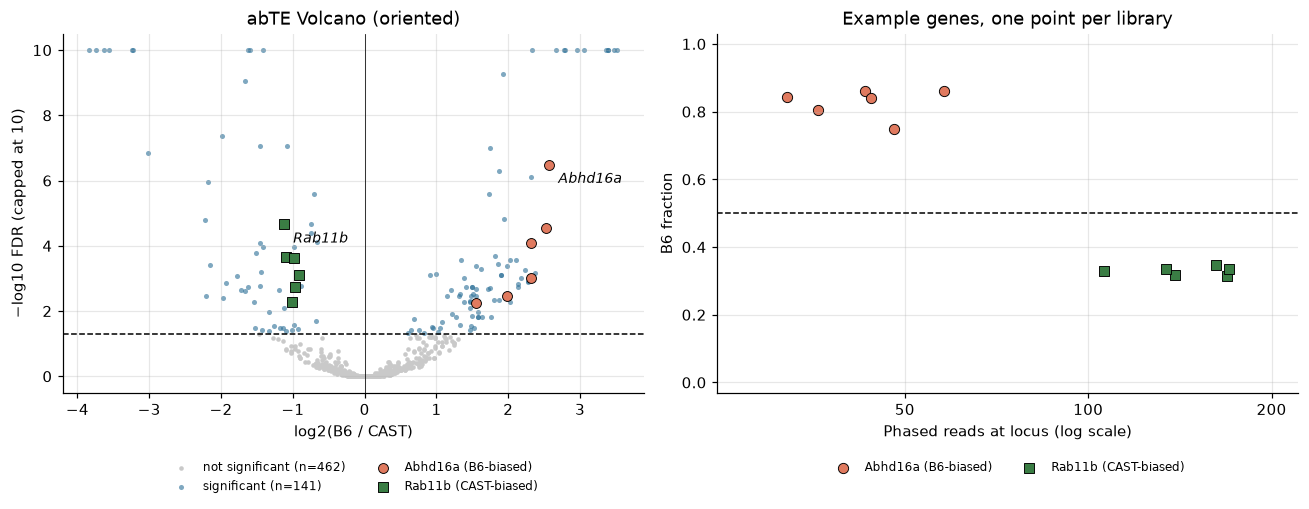

name,Abhd16a,Rab11b
sample,,
ENCFF100UBG,37 / 43 (0.86),56 / 162 (0.35)
ENCFF338YTG,50 / 58 (0.86),53 / 169 (0.31)
ENCFF509RDZ,37 / 44 (0.84),44 / 139 (0.32)
ENCFF605NQH,29 / 36 (0.81),35 / 106 (0.33)
ENCFF812RTU,27 / 32 (0.84),57 / 170 (0.34)
ENCFF937WKF,36 / 48 (0.75),45 / 134 (0.34)


In [70]:
MHC_MODE = "only"            # "only": pick MHC genes; "exclude": skip them; "any": no filter
MHC_START, MHC_END = 33_600_000, 38_000_000   # MHC window on chr17 (GRCm38); H2-* genes always count
PICK_OVERRIDE = {}           # force a gene by name, e.g. {"CAST-biased": "Ddx39b"}

# --- 1. Put LASER's calls on the B6/CAST scale ---------------------------------
GENE_COL = next((c for c in ["gene_key", "gene_id", "locus_id", "associated_gene", "gene", "locus"]
                 if c in ae.columns), None)
if GENE_COL is None:
    raise KeyError(f"No gene ID column found in allelic_effect_results.tsv: {list(ae.columns)}")
aeo = ae[~ae["sample"].isin(FAILED)].copy()
aeo["gene_key"] = aeo[GENE_COL].astype(str).str.replace(r"\.\d+.*$", "", regex=True)
# If LASER reports gene names rather than Ensembl IDs, map names back to IDs
name_to_key = {v: k for k, v in gene_map.items()}
aeo["gene_key"] = aeo["gene_key"].map(lambda g: g if g in gene_map else name_to_key.get(g, g))

aeo = aeo.merge(orient[["sample", "gene_key", "hap1_is_B6"]], on=["sample", "gene_key"], how="left")
tested = aeo["abte_fdr"].notna()
oriented = aeo["hap1_is_B6"].notna()
print(f"Gene ID column: {GENE_COL}")
print(f"abTE-tested locus–library pairs in the good libraries: {tested.sum()}; "
      f"oriented: {(tested & oriented).sum()} ({(tested & oriented).sum() / max(tested.sum(), 1):.0%})")
aeo = aeo[oriented].copy()

b6_first = aeo["hap1_is_B6"].astype(bool)
aeo["B6"] = np.where(b6_first, aeo["locus_hap1_reads"], aeo["locus_hap2_reads"])
aeo["CAST"] = np.where(b6_first, aeo["locus_hap2_reads"], aeo["locus_hap1_reads"])
aeo["total"] = aeo["B6"] + aeo["CAST"]
aeo["b6_frac"] = aeo["B6"] / aeo["total"]
aeo["lfc_b6"] = np.log2((aeo["B6"] + 0.5) / (aeo["CAST"] + 0.5))
# abte_sig is missing for loci LASER did not test; NaN.astype(bool) would be True,
# so parse it explicitly and keep only loci with an abTE FDR
aeo["sig"] = aeo["abte_sig"].map(lambda v: str(v).strip().lower() in ("true", "1", "1.0"))
aeo = aeo[aeo["abte_fdr"].notna()].copy()
print(f"Plotted: {len(aeo)} oriented abTE tests, {aeo['sig'].sum()} significant")
aeo["name"] = aeo["gene_key"].map(gname)

# --- 2. Flag MHC genes by name and position ------------------------------------
pos = genes_ref.set_index("gene_key")[["seqname", "start"]] if not genes_ref.empty else pd.DataFrame()
def is_mhc(key):
    if gname(key).startswith("H2-"):
        return True
    if key in pos.index:
        chrom, start = pos.loc[key].iloc[0] if isinstance(pos.loc[key], pd.DataFrame) else pos.loc[key]
        return str(chrom).replace("chr", "") == "17" and MHC_START <= start <= MHC_END
    return False

# --- 3. Rank genes: libraries called significant, then effect size ------------
sig_rows = aeo[aeo["sig"]]
rank = sig_rows.groupby("gene_key").agg(
    n_sig_libs=("sample", "nunique"),
    mean_lfc=("lfc_b6", "mean"),
    all_b6=("lfc_b6", lambda x: (x > 0).all()),
    all_cast=("lfc_b6", lambda x: (x < 0).all()),
)
rank["name"] = rank.index.map(gname)
rank["mhc"] = rank.index.map(is_mhc)
rank["start_mb"] = rank.index.map(
    lambda k: float(pos.loc[k, "start"].min() if isinstance(pos.loc[k], pd.DataFrame) else pos.loc[k, "start"]) / 1e6
    if k in pos.index else np.nan)
rank["abs_lfc"] = rank["mean_lfc"].abs()
rank = rank.sort_values(["n_sig_libs", "abs_lfc"], ascending=False)

picks = {}
for label, direction in [("B6-biased", "all_b6"), ("CAST-biased", "all_cast")]:
    cands = rank[rank[direction]]
    if MHC_MODE == "only":
        cands = cands[cands["mhc"]]
    elif MHC_MODE == "exclude":
        cands = cands[~cands["mhc"]]
    print(f"Top {label} candidates ({MHC_MODE} MHC): " + ", ".join(
        f"{r.name} ({r.n_sig_libs} libs, log2 {r.mean_lfc:+.1f}, {r.start_mb:.2f} Mb)"
        for r in cands.head(3).itertuples()))
    if label in PICK_OVERRIDE:
        hit = rank.index[rank["name"] == PICK_OVERRIDE[label]]
        if len(hit):
            picks[label] = hit[0]
            continue
        print(f"  PICK_OVERRIDE gene {PICK_OVERRIDE[label]!r} not found among significant genes; using the top candidate")
    if len(cands):
        picks[label] = cands.index[0]

display(rank.loc[list(picks.values()), ["name", "n_sig_libs", "mean_lfc", "start_mb", "mhc"]]
        .assign(example=list(picks.keys())).round(2))

# --- 4. Plot -------------------------------------------------------------------
PICK_STYLE = {"B6-biased": ("#e07a5f", "o"), "CAST-biased": ("#3a7d44", "s")}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ax = axes[0]
y = -np.log10(aeo["abte_fdr"].clip(lower=1e-10))
ax.scatter(aeo.loc[~aeo["sig"], "lfc_b6"], y[~aeo["sig"]], s=9, color="#c9c9c9", linewidths=0,
           label=f"not significant (n={(~aeo['sig']).sum()})")
ax.scatter(aeo.loc[aeo["sig"], "lfc_b6"], y[aeo["sig"]], s=11, color="#2a6f97", alpha=0.6, linewidths=0,
           label=f"significant (n={aeo['sig'].sum()})")
for label, key in picks.items():
    col, mk = PICK_STYLE[label]
    g = aeo[aeo["gene_key"] == key]
    gy = -np.log10(g["abte_fdr"].clip(lower=1e-10))
    ax.scatter(g["lfc_b6"], gy, s=42, color=col, marker=mk, edgecolor="k", linewidth=0.6, zorder=3,
               label=f"{gname(key)} ({label})")
    if gy.notna().any():
        top = gy.idxmax()
        ax.annotate(gname(key), (g.loc[top, "lfc_b6"], gy[top]), xytext=(6, -12), textcoords="offset points",
                    fontsize=9, fontstyle="italic")
ax.axhline(-np.log10(FDR_ALPHA), ls="--", color="k", lw=1)
ax.axvline(0, color="k", lw=0.5)
ax.set(xlabel="log2(B6 / CAST)", ylabel="−log10 FDR (capped at 10)", title="abTE Volcano (oriented)")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)

ax = axes[1]
for label, key in picks.items():
    col, mk = PICK_STYLE[label]
    g = aeo[aeo["gene_key"] == key]
    ax.scatter(g["total"], g["b6_frac"], s=45, color=col, marker=mk, edgecolor="k", linewidth=0.6,
               label=f"{gname(key)} ({label})")
ax.axhline(0.5, ls="--", color="k", lw=1)
ax.set(xscale="log", ylim=(-0.03, 1.03), xlabel="Phased reads at locus (log scale)", ylabel="B6 fraction",
       title="Example genes, one point per library")
from matplotlib.ticker import FixedLocator, ScalarFormatter, NullLocator
shown = aeo[aeo["gene_key"].isin(picks.values())]["total"]
if len(shown):
    lo, hi = shown.min() / 1.3, shown.max() * 1.3
    ticks = [t for t in [5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000] if lo <= t <= hi]
    ax.set_xlim(lo, hi)
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_locator(NullLocator())
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
finish(fig, "06_abte")

# Per-library values behind the right panel
ex = aeo[aeo["gene_key"].isin(picks.values())].copy()
ex["B6 / total (fraction)"] = (ex["B6"].astype(int).astype(str) + " / " + ex["total"].astype(int).astype(str)
                               + " (" + ex["b6_frac"].round(2).astype(str) + ")")
display(ex.pivot_table(index="sample", columns="name", values="B6 / total (fraction)", aggfunc="first"))


## 7. abTU: allelic bias in transcript usage

LASER's central question is whether **the two alleles of a gene produce a different mix of isoforms**. 

A variant can change splicing, TSS or polyA site usage without changing total expression, altering the protein or how the mRNA is regulated. Gene-level ASE (abTE) would miss these effects. Because both alleles share the same nucleus in an F1, consistent differences must be cis-acting, and long reads make the test possible by assigning each read to both an allele and an isoform. LASER compares the two allelic isoform mixes with a Dirichlet-multinomial test, using an overdispersion parameter (θ) pooled across loci. The effect size is the total variation distance (TVD), from 0 (identical mixes) to 1 (no shared isoforms).

Of the 635 locus–sample tests, 443 (70%) are significant (Fig. 7), most with TVD > 0.6. Many share the minimum attainable FDR (~0.0017), so the test's resolution, not the evidence, sets the ceiling. In this subsampled chr17 run these results show that the pipeline works rather than giving biological findings: with few reads per allele, isoform mixes can differ by chance, which inflates TVD. Allele-specific misalignment near splice sites could also create spurious differences. See the calibration warning in Section 8 before reading anything into these numbers.

≥10 reads: 635 loci, 70% significant
≥20 reads: 635 loci, 70% significant
≥50 reads: 339 loci, 74% significant


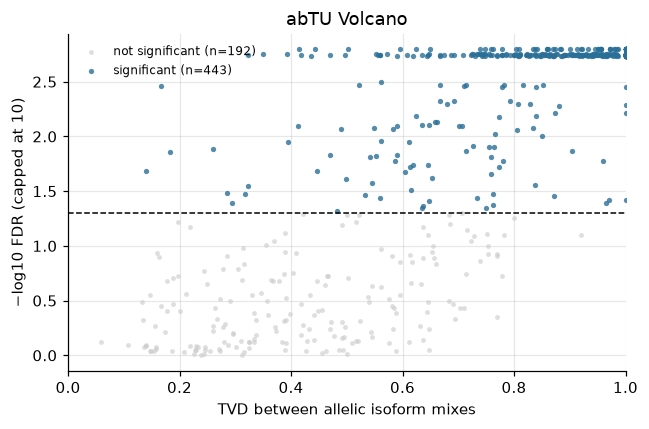

In [71]:
fig, ax = plt.subplots(figsize=(6, 4))
if not ae.empty and "abtu_tvd" in ae.columns:
    tu = ae[ae["abtu_tvd"].notna()]
    depth = tu["locus_hap1_reads"] + tu["locus_hap2_reads"]
    for thr in [10, 20, 50]:
        keep = depth >= thr
        print(f"≥{thr} reads: {keep.sum()} loci, {tu.loc[keep, 'abtu_sig'].astype(bool).mean():.0%} significant")
    sig = tu["abtu_sig"].astype(bool)
    y = -np.log10(tu["abtu_fdr"].clip(lower=1e-10))
    ax.scatter(tu.loc[~sig, "abtu_tvd"], y[~sig], s=10, alpha=0.6, color="#c9c9c9", linewidths=0,
               label=f"not significant (n={(~sig).sum()})")
    ax.scatter(tu.loc[sig, "abtu_tvd"], y[sig], s=12, alpha=0.8, color="#2a6f97", linewidths=0,
               label=f"significant (n={sig.sum()})")
    ax.axhline(-np.log10(FDR_ALPHA), ls="--", color="k", lw=1)
    ax.set(xlim=(0, 1), xlabel="TVD between allelic isoform mixes",
           ylabel="−log10 FDR (capped at 10)", title="abTU Volcano")
    ax.legend(frameon=False, loc="upper left", fontsize=8)
    ax.set_axisbelow(True)
finish(fig, "07_abtu_overview")

## 8. Why theta matters: calibration of the abTU test

Isoform counts are **overdispersed**: library prep, reverse transcription and PCR make the isoform mix vary more than a simple multinomial model expects, so a test that ignores this finds "significant" differences almost everywhere.

LASER's Dirichlet-multinomial test absorbs this extra variation through **θ**. `calibrate_pooled` picks θ using a set of calibration loci (2,000 on genome-wide data), choosing the value at which the false-positive rate on those loci is ~5%. The result is saved in `_theta/theta_pooled*.json` as `achieved_fpr` (the rate reached) and `nominal_fpr` (the 5% target), alongside `n_loci_used`. The next cell prints them.

In this run, calibration reached its target: `achieved_fpr` is 0.0465 against a `nominal_fpr` of 0.05. But it was fitted on only 635 locus–sample tests (`n_loci_used`) rather than 2,000 loci, so θ is less certain than on full data.

> **⚠ Warning: abTU results on this tutorial data are illustrative only.** The chr17 subset with ~10k reads per library gives a small, shallow calibration set, so θ and the abTU calls are much less certain than on full data. Use these results to learn how the outputs look, not as findings. Proper calibration needs full-depth, genome-wide data.

**How to read Fig. 8.** The QQ plot shows p-values for *all* tested loci, so it is **not** a calibration check. Genuine allelic effects push points above the diagonal by design: on full-depth genome-wide ENCODE data, ~36% of tested loci are significant even though the test is well calibrated. The right check is a QQ plot of the calibration (null) loci only, which should sit on the diagonal with ~5% of p-values below 0.05, and the `achieved_fpr` value printed below.

Many p-values here sit at the same minimum value. abTU p-values come from permutations, so the smallest possible p-value is 1/(n_permutations + 1). Points at that floor mean "at least this small", not "extremely strong evidence". Here 355 of 635 tests sit at the floor of 0.001 (1,000 permutations).


In [72]:
# Read the theta calibration record(s) written by calibrate_pooled
theta_files = sorted(AE_DIR.glob("_theta*/theta_pooled*.json")) or sorted(AE_DIR.rglob("theta*.json"))
if not theta_files:
    print("No theta JSON found under", AE_DIR)
for f in theta_files:
    rec = json.loads(f.read_text())
    print(f"{f.relative_to(OUT_DIR)}")
    if isinstance(rec, dict):
        for k, v in rec.items():
            if not isinstance(v, (list, dict)):
                print(f"  {k}: {v}")
        fpr = rec.get("achieved_fpr", rec.get("calibrated_fpr"))
        target = float(rec.get("nominal_fpr", 0.05))
        if fpr is not None:
            flag = "OK" if abs(float(fpr) - target) <= 0.02 else "CHECK: far from the target"
            print(f"  -> achieved FPR {float(fpr):.3f} vs target {target:.3f} ({flag})")
        n_used = rec.get("n_loci_used")
        if n_used is not None and int(n_used) < 2000:
            print(f"  -> only {n_used} loci used for calibration (2,000 on genome-wide data): θ is less certain")
    print()

# The p-value floor tells you the permutation resolution
if not ae.empty and ae["abtu_p_value"].notna().any():
    p_min = ae["abtu_p_value"].min()
    n_floor = (ae["abtu_p_value"] <= p_min * 1.0001).sum()
    print(f"Smallest abTU p-value: {p_min:.4g} (≈ 1/({1/p_min - 1:.0f} + 1) permutations); "
          f"{n_floor} of {ae['abtu_p_value'].notna().sum()} tests sit at this floor")


allelic_effect_testing/_theta/theta_pooled.json
  theta_mode: calibrate_pooled
  theta: 0.0866
  achieved_fpr: 0.0465
  nominal_fpr: 0.05
  n_loci_used: 635
  n_samples_pooled: 8
  seed: 456
  timestamp: 2026-10-08T09:14:22+0100
  -> achieved FPR 0.046 vs target 0.050 (OK)
  -> only 635 loci used for calibration (2,000 on genome-wide data): θ is less certain

Smallest abTU p-value: 0.000999 (≈ 1/(1000 + 1) permutations); 355 of 635 tests sit at this floor


p < 0.05: 72% of 635 tests (not expected to be 5%: real effects are included)
    abtu_theta abtu_theta_provenance
0          NaN                   NaN
32      0.0866      calibrate_pooled


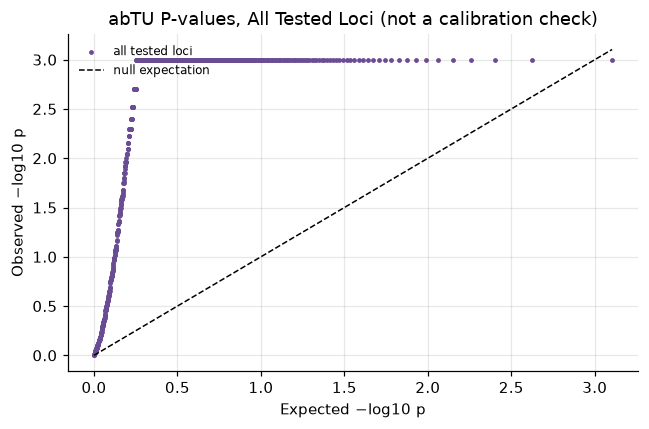

In [73]:
fig, ax = plt.subplots(figsize=(6, 4))
if not ae.empty:
    p = np.sort(ae["abtu_p_value"].dropna().clip(lower=1e-300).values)
    if len(p):
        n = len(p)
        exp = -np.log10((np.arange(1, n + 1) - 0.5) / n)
        obs = -np.log10(p)
        lim = max(exp.max(), obs.max())
        ax.scatter(exp, obs, s=10, color="#6a4c93", linewidths=0, label="all tested loci")
        ax.plot([0, lim], [0, lim], "k--", lw=1, label="null expectation")
        ax.set(xlabel="Expected −log10 p", ylabel="Observed −log10 p", title="abTU P-values, All Tested Loci (not a calibration check)")
        ax.legend(frameon=False, loc="upper left", fontsize=8)
        ax.set_axisbelow(True)
        print(f"p < 0.05: {(p < 0.05).mean():.0%} of {n} tests (not expected to be 5%: real effects are included)")
    print(ae[["abtu_theta", "abtu_theta_provenance"]].drop_duplicates())
finish(fig, "08_theta_calibration")

## 9. Four-way classification

LASER combines its two tests to place each locus in one of four classes: **both abTE and abTU**, **abTU without detectable abTE**, **abTE only**, or **no detectable allelic effect** (Fig. 9). The "abTU without abTE" class is the one gene-level ASE methods cannot see: total expression is balanced, but the alleles use different isoforms.

In this run, 305 of 635 tests are abTU without abTE, 138 show both effects, 175 show neither, and only 17 are abTE only. Because θ was calibrated on a small, shallow set of loci (Section 8), the abTU-containing classes should not be interpreted. These proportions demonstrate the classification rather than describe the biology.

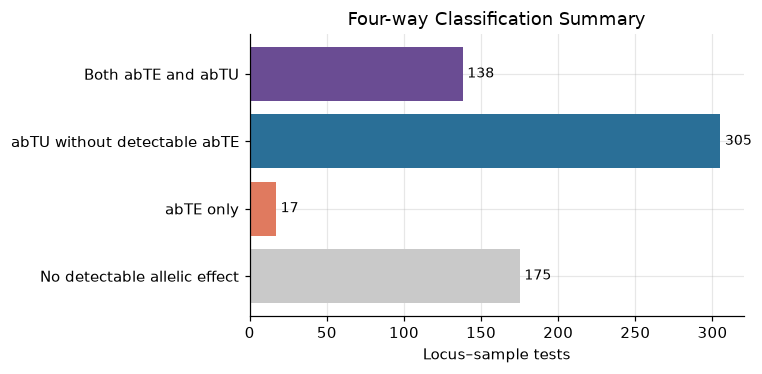

In [59]:
ORDER = ["Both abTE and abTU", "abTU without detectable abTE", "abTE only", "No detectable allelic effect"]
CLASS_COL = {"Both abTE and abTU": "#6a4c93", "abTU without detectable abTE": "#2a6f97",
             "abTE only": "#e07a5f", "No detectable allelic effect": "#c9c9c9"}

fig, ax = plt.subplots(figsize=(7, 3.5))
if not ae.empty:
    vc = ae["allelic_effect_class"].value_counts()
    vc = vc.reindex([c for c in ORDER if c in vc.index] + [c for c in vc.index if c not in ORDER])
    ax.barh(vc.index, vc.values, color=[CLASS_COL.get(c, "#2a6f97") for c in vc.index])
    for i, v in enumerate(vc.values):
        ax.text(v + vc.max() * 0.01, i, str(v), va="center", fontsize=9)
    ax.invert_yaxis()
    ax.set(xlabel="Locus–sample tests", title="Four-way Classification Summary")
    ax.set_axisbelow(True)
finish(fig, "09_classification_reproducibility")

## 10. Functional consequence: what changes between the alleles?

For every abTU-positive locus, LASER compares the two alleles' dominant transcripts and records how they differ: coding status, NMD target status, TSS, TES or ORF length. Fig. 10 shows, for each type of change, the proportion of abTU loci affected, averaged across libraries (bars) with individual libraries as points. These categories show *how* a cis variant could matter: for example, if one allele favours an NMD-targeted isoform, it can reduce functional protein without changing total RNA, which is invisible to gene-level ASE.



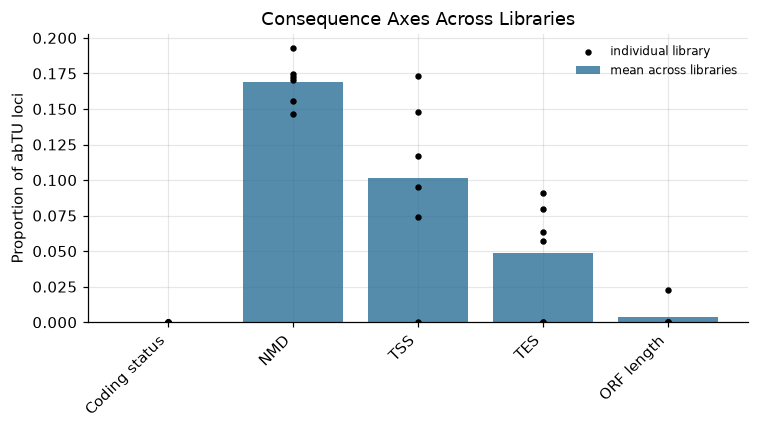

In [60]:
FAILED = ["ENCFF476MLA", "ENCFF683BZL"]
NICE = {"coding": "Coding status", "nmd": "NMD", "tss": "TSS", "tes": "TES", "orf_length": "ORF length"}

fig, ax = plt.subplots(figsize=(7, 4))
# Merged consequence table (one row per sample); fall back to the per-sample files if absent
conseq_path = AE_DIR / "overview/consequence_test_summary.tsv"
if conseq_path.exists():
    conseq = pd.read_csv(conseq_path, sep="\t")
else:
    conseq = pd.concat([pd.read_csv(AE_DIR / s / "consequence_manifest.tsv", sep="\t")
                        for s in SAMPLES if (AE_DIR / s / "consequence_manifest.tsv").exists()],
                       ignore_index=True)
if not conseq.empty:
    if "sample" in conseq.columns:
        conseq = conseq[~conseq["sample"].astype(str).str.contains("|".join(FAILED))]
    prop_cols = [c for c in conseq.columns if c.startswith("prop_sig_")]
    if prop_cols:
        x = np.arange(len(prop_cols))
        ax.bar(x, conseq[prop_cols].mean(), color="#2a6f97", alpha=0.8, label="mean across libraries")
        for i, c in enumerate(prop_cols):
            ax.scatter(np.full(len(conseq), i), conseq[c], color="k", s=10, zorder=3,
                       label="individual library" if i == 0 else None)
        ax.set_xticks(x)
        ax.set_xticklabels([NICE.get(c.removeprefix("prop_sig_"), c) for c in prop_cols],
                           rotation=45, ha="right")
        ax.set(ylabel="Proportion of abTU loci", title="Consequence Axes Across Libraries")
        ax.legend(frameon=False, fontsize=8)
        ax.set_axisbelow(True)
finish(fig, "10_consequence")

## 11. Report card

One row per library, combining every QC and result above. If `SAVE_OUTPUTS = True`, this table, the oriented allele counts and LASER's calls (with gene names and B6/CAST labels added) are written to `notebook_outputs/`, along with every figure.

In [16]:
card = pd.DataFrame(index=SAMPLES)
if not dv.empty: card = card.join(dv[["het_snvs", "ti_tv"]])
if not phasing.empty: card = card.join(phasing[["phased_frac"]])
if not ae.empty: card = card.join(ae.groupby("sample")[["abte_sig", "abtu_sig"]].sum())
display(card)

if SAVE_OUTPUTS:
    od = Path("notebook_outputs")
    od.mkdir(exist_ok=True)
    card.to_csv(od / "report_card.tsv", sep="\t")
    print(f"Report card saved to {od.resolve()}")

,het_snvs,ti_tv,phased_frac,abte_sig,abtu_sig
ENCFF100UBG,5252,2.662873,0.983375,21,63
ENCFF338YTG,6624,2.639655,0.985764,29,88
ENCFF476MLA,66,2.942857,0.466667,7,2
ENCFF509RDZ,6136,2.770782,0.982350,25,75
ENCFF605NQH,6540,2.620184,0.985251,19,57
ENCFF683BZL,72,1.750000,0.567164,1,0
ENCFF812RTU,5697,2.770449,0.987324,32,77
ENCFF937WKF,7118,2.577947,0.983775,21,81


Report card saved to /rds/user/hk627/hpc-work/allele-specific-expression-laser-mm/LASER-1.1/tutorial/scripts/notebook_outputs


## Other files or biological pathways to explore

- **Load the haplotagged BAMs** (`identify_loci/whatshap/<sample>/<sample>.flnc.hp.bam`) in IGV and colour or group reads by the `HP` tag. That gives a haplotype-split view of the same locus.
- **Scale up**: this subset is shallow by design. On full-depth libraries, many more loci clear the `min_phased_reads_per_locus` threshold and θ calibration becomes reliable. Partially imprinted genes can then be tested, but completely imprinted genes are still filtered out (Section 6).
- **Change theta**: rerun with `theta_mode = 'lift'` or `'fixed'` and compare section 8. With fewer than 3 samples, pooled calibration isn't available.